# What RT adds to PSCA CAR-T in the irradiated tumour — CD8 and macrophage figures

Two figures built from `code/mhcCytotoxExhaustion/` outputs (run that folder first). Every plotted
estimate, CI and p-value is recomputed here.

| figure | claim it supports |
|---|---|
| **1 — CD8** | In the irradiated tumour, RT goes with more Gzmb+, Cxcr3+ and Ccr5+ CD8 T cells in both CAR arms, and more inhibitory receptors, but not more Tox; with PSCA the CD8 effector / low-Nr4a shift is strongest |
| **2 — macrophages** | In the irradiated tumour, PSCA + RT goes with more Ciita and less Pvr and Cd80/Cd86 in macrophages (CAR × RT p < 0.05); the M1-like share, Il1b and PD-L1 (Cd274) move the same way but only as trends |

### Statistics
* **Unit = one tumour sample.** Fractions are the share of a sample's CD8 cells with ≥ 1 read
  of the gene (samples with ≥ 8 CD8 cells, as in `mhcCytotoxExhaustion/04`). Composition is the
  share of all cells in the sample.
* **Direct RT** = RT − no RT in Tu1 (the irradiated tumour), per CAR. **Pooled** = mean of the
  two CARs. **CAR × RT** = (RT effect in PSCA) − (RT effect in TAG72).
* **p-values: exact relabelling** within each stratum; pooled and CAR × RT use the combined
  null. With 3 v 3 tumours the smallest p within one CAR is 0.10 (0.20 at 3 v 2).
* **95% CIs:** pooled-variance t intervals.
* **Genes:** pydeseq2 0.5.4 fitted **on Tu1 samples only**, design `~ car + rt + car:rt`, so the
  CAR × RT test is specific to the irradiated tumour. The earlier both-site fit
  (`~ site + car + rt + car:rt`, `mhcCytotoxExhaustion/02`) is reported alongside.
* Composition panels also show the **Welch t-test** p used in `rtAdvantage/02`, because the
  exact test cannot go below 0.10 at 3 v 3.

## 1. Config, style and data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools, logging
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
logging.disable(logging.WARNING)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
SRC = PROJ/"results/mhc_cytotox"; COMP = PROJ/"results/rt_advantage/composition_counts_fine.csv"
OUT = PROJ/"results/psca_rt_figures"; PANELS = OUT/"panels"
OUT.mkdir(parents=True, exist_ok=True); PANELS.mkdir(parents=True, exist_ok=True)
for f_ in ["pseudobulk_counts.parquet", "pseudobulk_meta.csv", "cell_panel.parquet", "de_all.parquet",
           "exhaustion_per_sample.csv"]:
    assert (SRC/f_).exists(), f"run code/mhcCytotoxExhaustion first — missing {f_}"
assert COMP.exists(), "run code/rtAdvantage/01 first"
MIN_CELLS_PB, MIN_CELLS_FRAC, SEED = 10, 8, 0

# ---- style (same palette and chrome as mhcCytotoxFigures; validated with the dataviz checker) ----
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"
mpl.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6, "lines.solid_capstyle": "round",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300, "text.color": INK})

ARMS4 = ["CyPSCA", "RTCyPSCA", "CyT72", "RTCyT72"]
ARM_LAB = {"CyPSCA": "PSCA\nno RT", "RTCyPSCA": "PSCA\n+ RT", "CyT72": "TAG72\nno RT", "RTCyT72": "TAG72\n+ RT"}
CAR_OF = {"CyPSCA": "PSCA", "RTCyPSCA": "PSCA", "CyT72": "TAG72", "RTCyT72": "TAG72", "NoTx": "none"}
RT_OF = {"CyPSCA": False, "RTCyPSCA": True, "CyT72": False, "RTCyT72": True, "NoTx": False}
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}
NAME = {"IFN_stimulated_Mac": "M1-like\n(IFN-stim)", "M2_like_Mac": "M2-like", "Intermediate_Mac": "Intermediate",
        "SPP1_TAM": "SPP1-TAM", "Classical_Mono": "Classical\nmono", "CD8_T": "CD8 T"}


def norm_arm(a): return str(a).replace("TAG72", "T72")


def site_of(sample): return int(str(sample).split("_Tu")[1][0])


# ---- data --------------------------------------------------------------------------------------
PB = pd.read_parquet(SRC/"pseudobulk_counts.parquet")
PBM = pd.read_csv(SRC/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
PBM["arm"] = PBM.arm.map(norm_arm)
L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)
DE = pd.read_parquet(SRC/"de_all.parquet")
EXH = pd.read_csv(SRC/"exhaustion_per_sample.csv"); EXH["arm"] = EXH.arm.map(norm_arm)
cp = pd.read_parquet(SRC/"cell_panel.parquet", columns=["sample", "arm", "site", "ct2", "Cxcr3", "Ccr5", "Cxcr6"])
cp["arm"] = cp.arm.map(norm_arm)
print(f"{len(PB)} pseudobulks | {len(cp):,} cells | arms {sorted(PBM.arm.unique())}")

1158 pseudobulks | 93,548 cells | arms ['CyPSCA', 'CyT72', 'NoTx', 'RTCyPSCA', 'RTCyT72']


## 2. Statistics engine (inline; same definitions as `mhcCytotoxFigures`)

In [2]:
def _cell(v, meta, A, B, site):
    idx = [i for i in meta.index[meta.arm.isin([A, B]) & (meta.site == site)] if np.isfinite(v.get(i, np.nan))]
    a = v[[i for i in idx if meta.loc[i, "arm"] == A]]; b = v[[i for i in idx if meta.loc[i, "arm"] == B]]
    if len(a) < 2 or len(b) < 2: return None
    x = np.r_[a.values, b.values]; k = len(a)
    null = [a.mean() - b.mean()]
    for c in itertools.combinations(range(len(x)), k):
        if c == tuple(range(k)): continue
        m = np.isin(np.arange(len(x)), c); null.append(x[m].mean() - x[~m].mean())
    ss = ((a - a.mean()) ** 2).sum() + ((b - b.mean()) ** 2).sum()
    return dict(d=a.mean() - b.mean(), null=np.array(null), ss=ss, df=len(a) + len(b) - 2,
                inv=1 / len(a) + 1 / len(b), nA=len(a), nB=len(b), a=a.values, b=b.values)


def _combine(nulls, how="mean", cap=60000, seed=SEED):
    g_ = np.random.default_rng(seed); out = nulls[0]
    for k, nb in enumerate(nulls[1:], start=2):
        out = ((out[:, None] * (k - 1) + nb[None, :]) / k).ravel() if how == "mean" else (out[:, None] - nb[None, :]).ravel()
        if len(out) > cap: out = np.r_[out[:1], g_.choice(out[1:], cap, replace=False)]
    return out


def _p(null): return float((np.abs(null) >= abs(null[0]) - 1e-12).mean())


def stratum(v, meta, cells):
    cs = [c for c in (_cell(v, meta, *cell) for cell in cells) if c is not None]
    if not cs: return None
    K = len(cs); df = sum(c["df"] for c in cs); s2 = sum(c["ss"] for c in cs) / max(df, 1)
    welch = stats.ttest_ind(cs[0]["a"], cs[0]["b"], equal_var=False).pvalue if K == 1 else np.nan
    return dict(d=np.mean([c["d"] for c in cs]), se=np.sqrt(s2 * sum(c["inv"] for c in cs)) / K, df=df,
                null=_combine([c["null"] for c in cs]), n=" + ".join(f"{c['nA']}v{c['nB']}" for c in cs), welch=welch)


EFFECTS = {   # name: two strata; CAR x RT is always (RT effect in PSCA) - (RT effect in TAG72)
    "direct RT":   [("PSCA", [("RTCyPSCA", "CyPSCA", 1)]), ("TAG72", [("RTCyT72", "CyT72", 1)])],
    "indirect RT": [("PSCA", [("RTCyPSCA", "CyPSCA", 2)]), ("TAG72", [("RTCyT72", "CyT72", 2)])],
    "PSCA Tu1":    [("no RT", [("CyPSCA", "CyT72", 1)]), ("RT", [("RTCyPSCA", "RTCyT72", 1)])],
    "PSCA Tu2":    [("no RT", [("CyPSCA", "CyT72", 2)]), ("RT", [("RTCyPSCA", "RTCyT72", 2)])],
}


def effect(v, meta, eff, scale=1.0):
    out = {}
    st = [(lab, stratum(v, meta, cells)) for lab, cells in EFFECTS[eff]]
    for lab, s in st:
        if s is None: continue
        h = stats.t.ppf(0.975, s["df"]) * s["se"]
        out[lab] = dict(est=s["d"] * scale, lo=(s["d"] - h) * scale, hi=(s["d"] + h) * scale,
                        p=_p(s["null"]), welch=s["welch"], n=s["n"])
    if all(s is not None for _, s in st):
        (l1, s1), (l2, s2) = st
        df = s1["df"] + s2["df"]; m = (s1["d"] + s2["d"]) / 2
        h = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2) / 2
        out["pooled"] = dict(est=m * scale, lo=(m - h) * scale, hi=(m + h) * scale,
                             p=_p(_combine([s1["null"], s2["null"]], "mean")))
        hi_, lo_ = (s2, s1) if eff.startswith("PSCA") else (s1, s2)
        it = hi_["d"] - lo_["d"]; hh = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2)
        out["CARxRT"] = dict(est=it * scale, lo=(it - hh) * scale, hi=(it + hh) * scale,
                             p=_p(_combine([hi_["null"], lo_["null"]], "diff")))
    return out


def flat(res, **keys):
    rows = []
    for k, d in res.items():
        if isinstance(d, dict): rows.append({**keys, "part": k, **{kk: vv for kk, vv in d.items()}})
    return rows


def fmt_p(p):
    if p is None or not np.isfinite(p): return "n/a"
    return f"{p:.3f}" if p < 0.01 else f"{p:.2f}"

## 3. Per-site CAR × RT DESeq2 (Tu1-only and Tu2-only fits; cached)
The both-site fit in `mhcCytotoxExhaustion/02` cannot say whether a CAR × RT gene effect belongs
to the irradiated tumour. Here each site is fitted on its own with `~ car + rt + car:rt`, and five
contrasts are read from one fit: PSCA effect without RT, PSCA effect with RT, RT effect in TAG72,
RT effect in PSCA, and the interaction.

In [3]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference
INF = DefaultInference(n_cpus=4)

FIT_GROUPS = ["IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "SPP1_TAM", "Classical_Mono", "CD8_T"]
FOCUS = ["Ciita", "Cd274", "Pvr", "Il1b", "Cd86", "Cd80", "H2-Ab1", "Cd74", "Cxcl9", "Spp1", "Nos2", "Mrc1", "Arg1",
         "Gzmb", "Gzmk", "Prf1", "Cxcr6", "Cxcr3", "Ccr5", "Pdcd1", "Havcr2", "Lag3", "Tox", "Tcf7", "Nr4a1", "Nr4a3", "Klf2"]
CACHE = OUT/"persite_carxrt_de.parquet"


def fit_site(group, site):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS_PB) & (PBM.site == site) & PBM.arm.isin(ARMS4)]
    meta = pd.DataFrame(index=d.index)
    meta["car"] = pd.Categorical(d.arm.map(CAR_OF), ["TAG72", "PSCA"])
    meta["rt"] = pd.Categorical(np.where(d.arm.map(RT_OF), "RT", "noRT"), ["noRT", "RT"])
    cnt = d.arm.value_counts().reindex(ARMS4).fillna(0).astype(int)
    if (cnt < 2).any(): return None, f"cells {cnt.to_dict()}"
    X = PB.loc[d.index]
    keep = (((X > 0).sum(0) >= 3) & (X.sum(0) >= 10 * len(X))) | (X.columns.isin(FOCUS) & ((X > 0).sum(0) >= 2))
    X = X.loc[:, keep]
    dds = DeseqDataSet(counts=X, metadata=meta, design="~ car + rt + car:rt", inference=INF, quiet=True)
    dds.deseq2()
    cols = list(dds.obsm["design_matrix"].columns)
    ic = [c for c in cols if ":" in c][0]; cc = [c for c in cols if c.startswith("car") and ":" not in c][0]
    rc = [c for c in cols if c.startswith("rt") and ":" not in c][0]
    vecs = {"PSCA_noRT": {cc: 1}, "PSCA_RT": {cc: 1, ic: 1}, "RT_in_TAG72": {rc: 1}, "RT_in_PSCA": {rc: 1, ic: 1},
            "CARxRT": {ic: 1}}
    out = []
    for name, w in vecs.items():
        v = np.zeros(len(cols))
        for c, x in w.items(): v[cols.index(c)] = x
        st = DeseqStats(dds, contrast=v, inference=INF, quiet=True); st.summary()
        r = st.results_df.copy(); r["gene"] = r.index; r["contrast"] = name
        out.append(r)
    r = pd.concat(out, ignore_index=True)
    r["group"], r["site"], r["n"] = group, site, " ".join(f"{a}:{n}" for a, n in cnt.items())
    return r, "ok"


if CACHE.exists():
    PS = pd.read_parquet(CACHE); print(f"loaded cached per-site fits: {CACHE.name} ({len(PS):,} rows)")
else:
    res, log = [], []
    for g in FIT_GROUPS:
        for s in (1, 2):
            r, msg = fit_site(g, s); log.append((g, s, msg)); print(f"  {g:20s} Tu{s}: {msg}")
            if r is not None: res.append(r)
    PS = pd.concat(res, ignore_index=True); PS.to_parquet(CACHE)
PSF = PS[PS.gene.isin(FOCUS)].copy()
print(PSF[PSF.contrast == "CARxRT"].pivot_table(index="gene", columns=["site", "group"], values="pvalue").round(3)
      .loc[lambda t: t.index.isin(["Ciita", "Cd274", "Pvr", "Il1b", "Cd86", "Cd80", "Cxcr6", "Gzmk", "Nr4a1", "Nr4a3", "Pdcd1"])]
      .to_string())

loaded cached per-site fits: persite_carxrt_de.parquet (578,535 rows)
site       1                                                                                      2                                                         
group  CD8_T Classical_Mono IFN_stimulated_Mac Intermediate_Mac M2_like_Mac SPP1_TAM Classical_Mono IFN_stimulated_Mac Intermediate_Mac M2_like_Mac SPP1_TAM
gene                                                                                                                                                        
Cd274  0.204          0.088              0.286            0.438       0.221    0.408          0.123              0.291            0.094       0.476    0.698
Cd80   0.795          0.002              0.001            0.006       0.037    0.251          0.478              0.363            0.302       0.431    0.444
Cd86   0.837          0.003              0.002            0.010       0.008    0.010          0.235              0.207            0.202       0.2

## 4. Figure 1 — CD8 T cells in the irradiated tumour

In [4]:
# ---- per-sample CD8 table: exhaustion fractions (04) + chemokine-receptor fractions (cell level) ----
c8 = EXH[(EXH["pop"] == "CD8_T") & (EXH.n >= MIN_CELLS_FRAC)].set_index("sample")
rec = (cp[cp.ct2 == "CD8_T"].assign(**{f"{g}+": lambda d, g=g: (d[g] > 0).astype(float) for g in ["Cxcr3", "Ccr5", "Cxcr6"]})
       .groupby("sample")[["Cxcr3+", "Ccr5+", "Cxcr6+"]].mean())
c8 = c8.join(rec)
c8["site"] = [site_of(s) for s in c8.index]
meta8 = c8[["arm", "site"]]

MARKERS = [("Effector / homing", ["Gzmb+", "Prf1+", "Cxcr3+", "Ccr5+", "Cxcr6+"]),
           ("Inhibitory receptors", ["IR_ge2", "Pdcd1+", "Havcr2+", "Lag3+", "Tigit+"]),
           ("Exhaustion TF / stem-like", ["Tox+", "Tcf7+"])]
MLAB = {"IR_ge2": "≥ 2 inhibitory receptors"}
rows = []
for fam, ms in MARKERS:
    for m in ms:
        rows += flat(effect(c8[m], meta8, "direct RT", scale=100), marker=m, family=fam, effect="direct RT")
        rows += flat(effect(c8[m], meta8, "indirect RT", scale=100), marker=m, family=fam, effect="indirect RT")
CD8E = pd.DataFrame(rows)
CD8E.to_csv(OUT/"fig1_cd8_effects.csv", index=False)
c8.to_csv(OUT/"fig1_cd8_per_sample.csv")
chk = CD8E[(CD8E.effect == "direct RT") & (CD8E.part == "pooled")].set_index("marker")[["est", "p"]]
print("direct RT, pooled over CARs (pp):"); print(chk.round(3).to_string())
print("\nCD8 samples used per arm x site:", c8.groupby(["arm", "site"]).size().to_dict())

direct RT, pooled over CARs (pp):
            est     p
marker               
Gzmb+    30.215  0.03
Prf1+    -2.161  0.54
Cxcr3+   12.518  0.01
Ccr5+    21.952  0.03
Cxcr6+   14.389  0.14
IR_ge2   17.323  0.03
Pdcd1+   -3.003  0.50
Havcr2+   8.883  0.04
Lag3+     7.701  0.03
Tigit+    5.140  0.19
Tox+    -18.145  0.07
Tcf7+   -19.871  0.05

CD8 samples used per arm x site: {('CyPSCA', 1): 3, ('CyPSCA', 2): 1, ('CyT72', 1): 2, ('CyT72', 2): 1, ('NoTx', 2): 1, ('RTCyPSCA', 1): 2, ('RTCyPSCA', 2): 2, ('RTCyT72', 1): 3, ('RTCyT72', 2): 3}


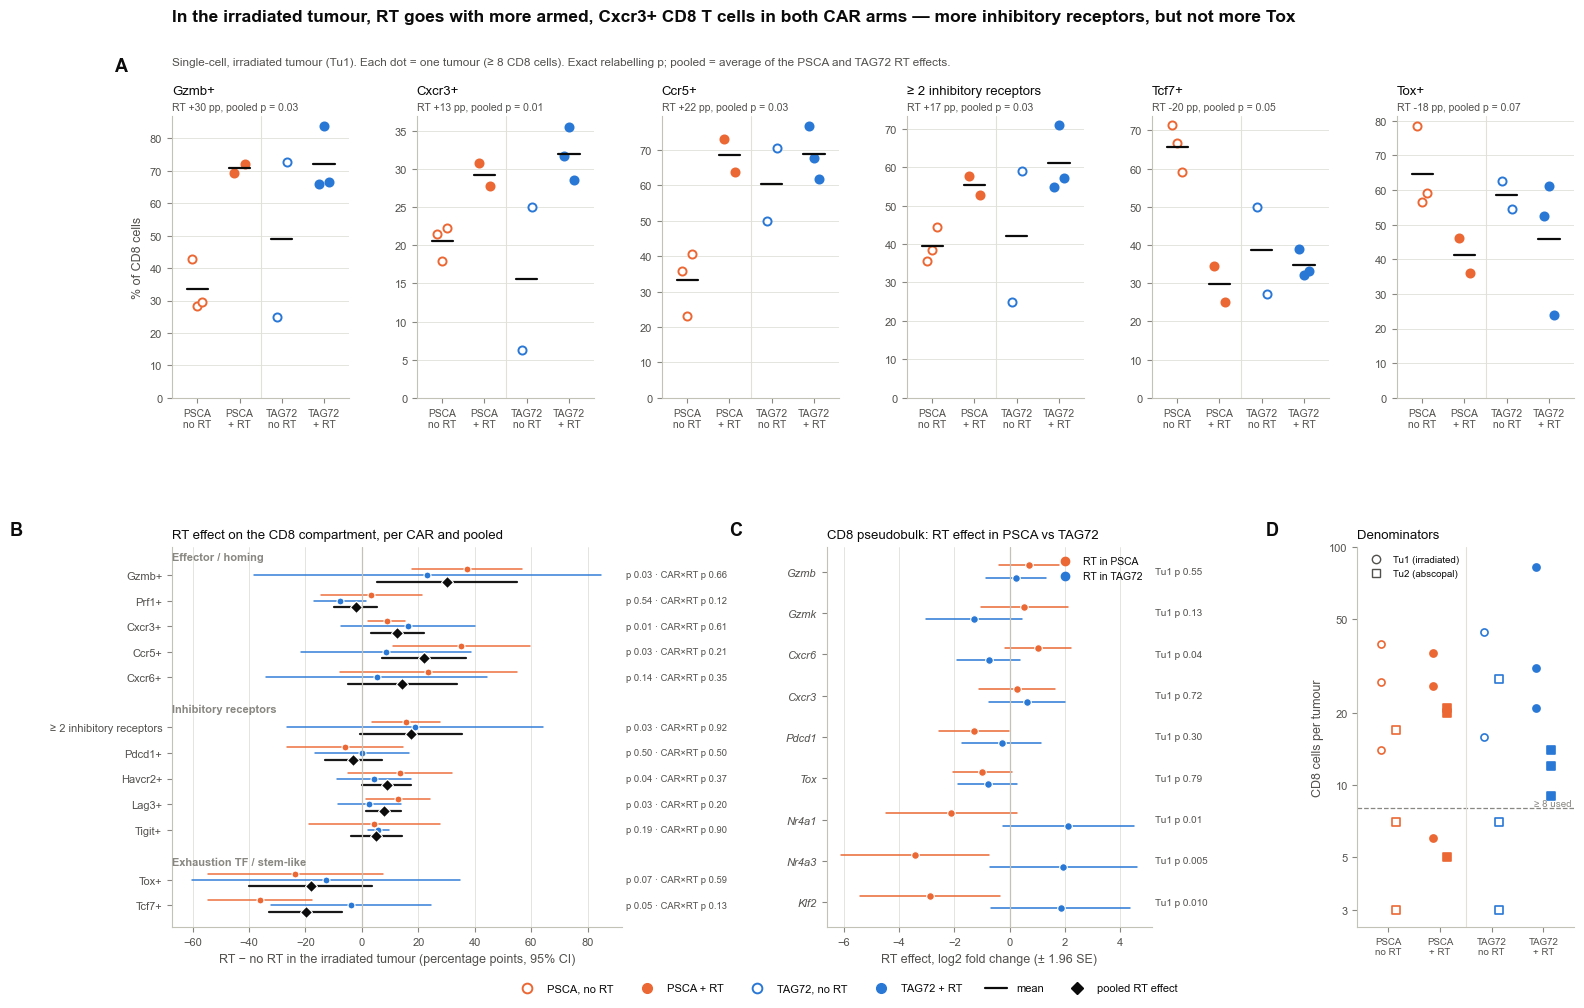

In [5]:
def strip(ax, df, col, site=1, scale=100, ylab=None, title=None):
    d = df[df.site == site]
    for i, arm in enumerate(ARMS4):
        v = d.loc[d.arm == arm, col].dropna() * scale
        n = d.loc[d.arm == arm, "n"] if "n" in d else None
        col_ = CAR_COL[CAR_OF[arm]]; filled = RT_OF[arm]
        xs = i + np.linspace(-0.12, 0.12, len(v)) if len(v) > 1 else np.array([i])
        ax.scatter(xs, v, s=34, marker="o", facecolor=col_ if filled else "white", edgecolor=col_, linewidth=1.4, zorder=3)
        if len(v): ax.plot([i - 0.25, i + 0.25], [v.mean()] * 2, color=INK, lw=1.6, zorder=4)
    ax.set_xticks(range(4)); ax.set_xticklabels([ARM_LAB[a] for a in ARMS4], fontsize=7.5)
    ax.set_xlim(-0.6, 3.6); ax.axvline(1.5, color=GRID, lw=0.8)
    ax.yaxis.grid(True); ax.set_axisbelow(True)
    if ylab: ax.set_ylabel(ylab)
    if title: ax.set_title(title, loc="left", fontsize=9.5, color=INK)


def legend_arms(fig, y=0.005, extra=()):
    h = [Line2D([], [], marker="o", ls="", mfc="white", mec=C_PSCA, mew=1.4, ms=7, label="PSCA, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec=C_PSCA, ms=7, label="PSCA + RT"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=C_TAG72, mew=1.4, ms=7, label="TAG72, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec=C_TAG72, ms=7, label="TAG72 + RT"),
         Line2D([], [], color=INK, lw=1.6, label="mean")] + list(extra)
    fig.legend(handles=h, loc="lower center", ncol=len(h), frameon=False, bbox_to_anchor=(0.5, y))


fig = plt.figure(figsize=(15, 10.2))
gs = GridSpec(2, 1, height_ratios=[1, 1.35], hspace=0.45, left=0.05, right=0.985, top=0.875, bottom=0.08)
fig.suptitle("In the irradiated tumour, RT goes with more armed, Cxcr3+ CD8 T cells in both CAR arms — "
             "more inhibitory receptors, but not more Tox", x=0.05, ha="left", fontsize=12.5, color=INK, weight="bold")
fig.text(0.05, 0.925, "Single-cell, irradiated tumour (Tu1). Each dot = one tumour (≥ 8 CD8 cells). Exact relabelling p; "
         "pooled = average of the PSCA and TAG72 RT effects.", fontsize=8.5, color=INK2)

# A: per-sample fractions
top = GridSpecFromSubplotSpec(1, 6, gs[0], wspace=0.38)
for j, m in enumerate(["Gzmb+", "Cxcr3+", "Ccr5+", "IR_ge2", "Tcf7+", "Tox+"]):
    ax = fig.add_subplot(top[j])
    r = CD8E[(CD8E.marker == m) & (CD8E.effect == "direct RT")].set_index("part")
    strip(ax, c8, m, ylab="% of CD8 cells" if j == 0 else None)
    ax.set_title(MLAB.get(m, m), loc="left", fontsize=9.5, pad=16)
    ax.text(0.0, 1.015, f"RT {r.loc['pooled', 'est']:+.0f} pp, pooled p = {fmt_p(r.loc['pooled', 'p'])}",
            transform=ax.transAxes, fontsize=7.5, color=INK2, va="bottom")
    ax.set_ylim(bottom=min(0, ax.get_ylim()[0]))
    if j == 0: ax.text(-0.32, 1.16, "A", transform=ax.transAxes, fontsize=13, weight="bold")

bot = GridSpecFromSubplotSpec(1, 3, gs[1], width_ratios=[1.45, 1.05, 0.7], wspace=0.62)
# B: forest of direct RT effects
ax = fig.add_subplot(bot[0]); ax.text(-0.36, 1.03, "B", transform=ax.transAxes, fontsize=13, weight="bold")
D = CD8E[CD8E.effect == "direct RT"]
y, ticks, labs, fam_y = 0, [], [], []
for fam, ms in MARKERS:
    fam_y.append((y - 0.2, fam)); y -= 0.7
    for m in ms:
        r = D[D.marker == m].set_index("part")
        for off, part, col_, mk in [(0.22, "PSCA", C_PSCA, "o"), (0.0, "TAG72", C_TAG72, "o"), (-0.26, "pooled", INK, "D")]:
            if part not in r.index: continue
            e = r.loc[part]
            ax.plot([e.lo, e.hi], [y + off] * 2, color=col_, lw=1.6 if part == "pooled" else 1.1, alpha=0.95)
            ax.plot(e.est, y + off, marker=mk, color=col_, ms=6 if part == "pooled" else 5, mec="white", mew=0.8)
        txt = f"p {fmt_p(r.loc['pooled', 'p'])}" + (f" · CAR×RT p {fmt_p(r.loc['CARxRT', 'p'])}" if "CARxRT" in r.index else "")
        ax.text(1.01, y, txt, transform=ax.get_yaxis_transform(), fontsize=6.8, va="center", color=INK2)
        ticks.append(y); labs.append(MLAB.get(m, m)); y -= 1
    y -= 0.25
for yy, fam in fam_y:
    ax.text(0.0, yy, fam, transform=ax.get_yaxis_transform(), fontsize=8, color=MUTED, weight="bold", va="bottom", ha="left")
ax.axvline(0, color=AXIS, lw=0.9); ax.set_yticks(ticks); ax.set_yticklabels(labs)
ax.set_ylim(y + 0.4, 0.4); ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.set_xlabel("RT − no RT in the irradiated tumour (percentage points, 95% CI)")
ax.set_title("RT effect on the CD8 compartment, per CAR and pooled", loc="left", fontsize=9.5)

# C: gene-level RT effect in PSCA vs TAG72 (Tu1-only DESeq2)
ax = fig.add_subplot(bot[1]); ax.text(-0.3, 1.03, "C", transform=ax.transAxes, fontsize=13, weight="bold")
GENES_C = ["Gzmb", "Gzmk", "Cxcr6", "Cxcr3", "Pdcd1", "Tox", "Nr4a1", "Nr4a3", "Klf2"]
g8 = PSF[(PSF.group == "CD8_T") & (PSF.site == 1)]
both = DE[(DE.group == "CD8_T") & (DE.contrast == "CARxRT")].set_index("gene")
GC = []
for i, gname in enumerate(GENES_C):
    r = g8[g8.gene == gname].set_index("contrast")
    if r.empty: continue
    yy = -i
    for part, col_, off in [("RT_in_PSCA", C_PSCA, 0.15), ("RT_in_TAG72", C_TAG72, -0.15)]:
        e = r.loc[part]; ax.plot([e.log2FoldChange - 1.96 * e.lfcSE, e.log2FoldChange + 1.96 * e.lfcSE], [yy + off] * 2,
                                 color=col_, lw=1.1)
        ax.plot(e.log2FoldChange, yy + off, "o", color=col_, ms=5.5, mec="white", mew=0.8)
    pi = r.loc["CARxRT", "pvalue"]; pb = both.pvalue.get(gname, np.nan)
    ax.text(1.01, yy, f"Tu1 p {fmt_p(pi)}", transform=ax.get_yaxis_transform(), fontsize=7.2, va="center", color=INK2)
    GC.append(dict(gene=gname, rt_psca=r.loc["RT_in_PSCA", "log2FoldChange"], rt_tag72=r.loc["RT_in_TAG72", "log2FoldChange"],
                   carxrt_tu1=r.loc["CARxRT", "log2FoldChange"], p_carxrt_tu1=pi, p_carxrt_bothsites=pb, n=r.n.iloc[0]))
ax.axvline(0, color=AXIS, lw=0.9)
ax.set_yticks([-i for i in range(len(GENES_C))]); ax.set_yticklabels(GENES_C, style="italic")
ax.set_ylim(-len(GENES_C) + 0.4, 0.6); ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.set_xlabel("RT effect, log2 fold change (± 1.96 SE)")
ax.set_title("CD8 pseudobulk: RT effect in PSCA vs TAG72", loc="left", fontsize=9.5)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=C_PSCA, label="RT in PSCA"),
                   Line2D([], [], marker="o", ls="", color=C_TAG72, label="RT in TAG72")],
          loc="upper right", frameon=False, fontsize=7.5)
pd.DataFrame(GC).to_csv(OUT/"fig1_cd8_genes_tu1.csv", index=False)

# D: denominators
ax = fig.add_subplot(bot[2]); ax.text(-0.42, 1.03, "D", transform=ax.transAxes, fontsize=13, weight="bold")
allc8 = EXH[EXH["pop"] == "CD8_T"].copy(); allc8["site"] = [site_of(s) for s in allc8["sample"]]
for i, arm in enumerate(ARMS4):
    for s, mk, off in [(1, "o", -0.14), (2, "s", 0.14)]:
        v = allc8[(allc8.arm == arm) & (allc8.site == s)].n
        col_ = CAR_COL[CAR_OF[arm]]
        ax.scatter(np.full(len(v), i + off), v, marker=mk, s=26, facecolor=col_ if RT_OF[arm] else "white",
                   edgecolor=col_, linewidth=1.2, zorder=3)
ax.axhline(MIN_CELLS_FRAC, color=MUTED, ls="--", lw=0.9)
ax.text(3.55, MIN_CELLS_FRAC, f"≥ {MIN_CELLS_FRAC} used", fontsize=7, color=MUTED, ha="right", va="bottom")
ax.set_yscale("log"); ax.set_yticks([3, 5, 10, 20, 50, 100]); ax.set_yticklabels(["3", "5", "10", "20", "50", "100"])
ax.minorticks_off(); ax.set_xticks(range(4)); ax.set_xticklabels([ARM_LAB[a] for a in ARMS4], fontsize=7)
ax.set_xlim(-0.6, 3.6); ax.axvline(1.5, color=GRID, lw=0.8); ax.set_ylabel("CD8 cells per tumour")
ax.set_title("Denominators", loc="left", fontsize=9.5)
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, label="Tu1 (irradiated)"),
                   Line2D([], [], marker="s", ls="", mfc="white", mec=INK2, label="Tu2 (abscopal)")],
          loc="upper left", frameon=False, fontsize=7)

legend_arms(fig, extra=[Line2D([], [], marker="D", ls="", color=INK, label="pooled RT effect")])
for ext in ("png", "pdf"): fig.savefig(OUT/f"Figure1_CD8_irradiated.{ext}", bbox_inches="tight")
plt.show()

## 5. Figure 2 — macrophages in the irradiated tumour

In [6]:
# ---- composition: share of all cells per sample -------------------------------------------------
cc = pd.read_csv(COMP).set_index("sample")
frac = cc.div(cc.sum(1), axis=0)
cm = pd.DataFrame({"arm": [norm_arm(s.split("_Tu")[0]) for s in frac.index], "site": [site_of(s) for s in frac.index]},
                  index=frac.index)
frac["M1_to_M2_log2"] = np.log2(frac.M1_like_Mac / frac.M2_like_Mac)
crow = []
for ct in ["M1_like_Mac", "M2_like_Mac", "M1_to_M2_log2"]:
    sc = 1 if ct == "M1_to_M2_log2" else 100
    for eff in ["PSCA Tu1", "PSCA Tu2", "direct RT", "indirect RT"]:
        crow += flat(effect(frac[ct], cm, eff, scale=sc), cell_type=ct, effect=eff)
COMPE = pd.DataFrame(crow); COMPE.to_csv(OUT/"fig2_composition_effects.csv", index=False)
frac.join(cm).to_csv(OUT/"fig2_composition_per_sample.csv")
print(COMPE[COMPE.part.isin(["no RT", "RT", "PSCA", "TAG72", "CARxRT"])]
      .pivot_table(index=["cell_type", "effect"], columns="part", values=["est", "p", "welch"]).round(3).to_string())

                             est                                    p                        welch                     
part                      CARxRT   PSCA      RT  TAG72   no RT CARxRT PSCA   RT TAG72 no RT   PSCA     RT  TAG72  no RT
cell_type     effect                                                                                                   
M1_like_Mac   PSCA Tu1     5.851    NaN  12.268    NaN   6.417  0.495  NaN  0.1   NaN   0.1    NaN  0.036    NaN  0.306
              PSCA Tu2    -5.203    NaN   9.283    NaN  14.486  0.555  NaN  0.1   NaN   0.1    NaN  0.017    NaN  0.042
              direct RT    5.851  7.616     NaN  1.765     NaN  0.345  0.1  NaN   0.7   NaN  0.077    NaN  0.737    NaN
              indirect RT -5.203 -4.102     NaN  1.101     NaN  0.200  0.4  NaN   1.0   NaN  0.311    NaN  0.568    NaN
M1_to_M2_log2 PSCA Tu1    -0.060    NaN   1.497    NaN   1.557  0.935  NaN  0.1   NaN   0.1    NaN  0.062    NaN  0.166
              PSCA Tu2    -0.717    NaN 

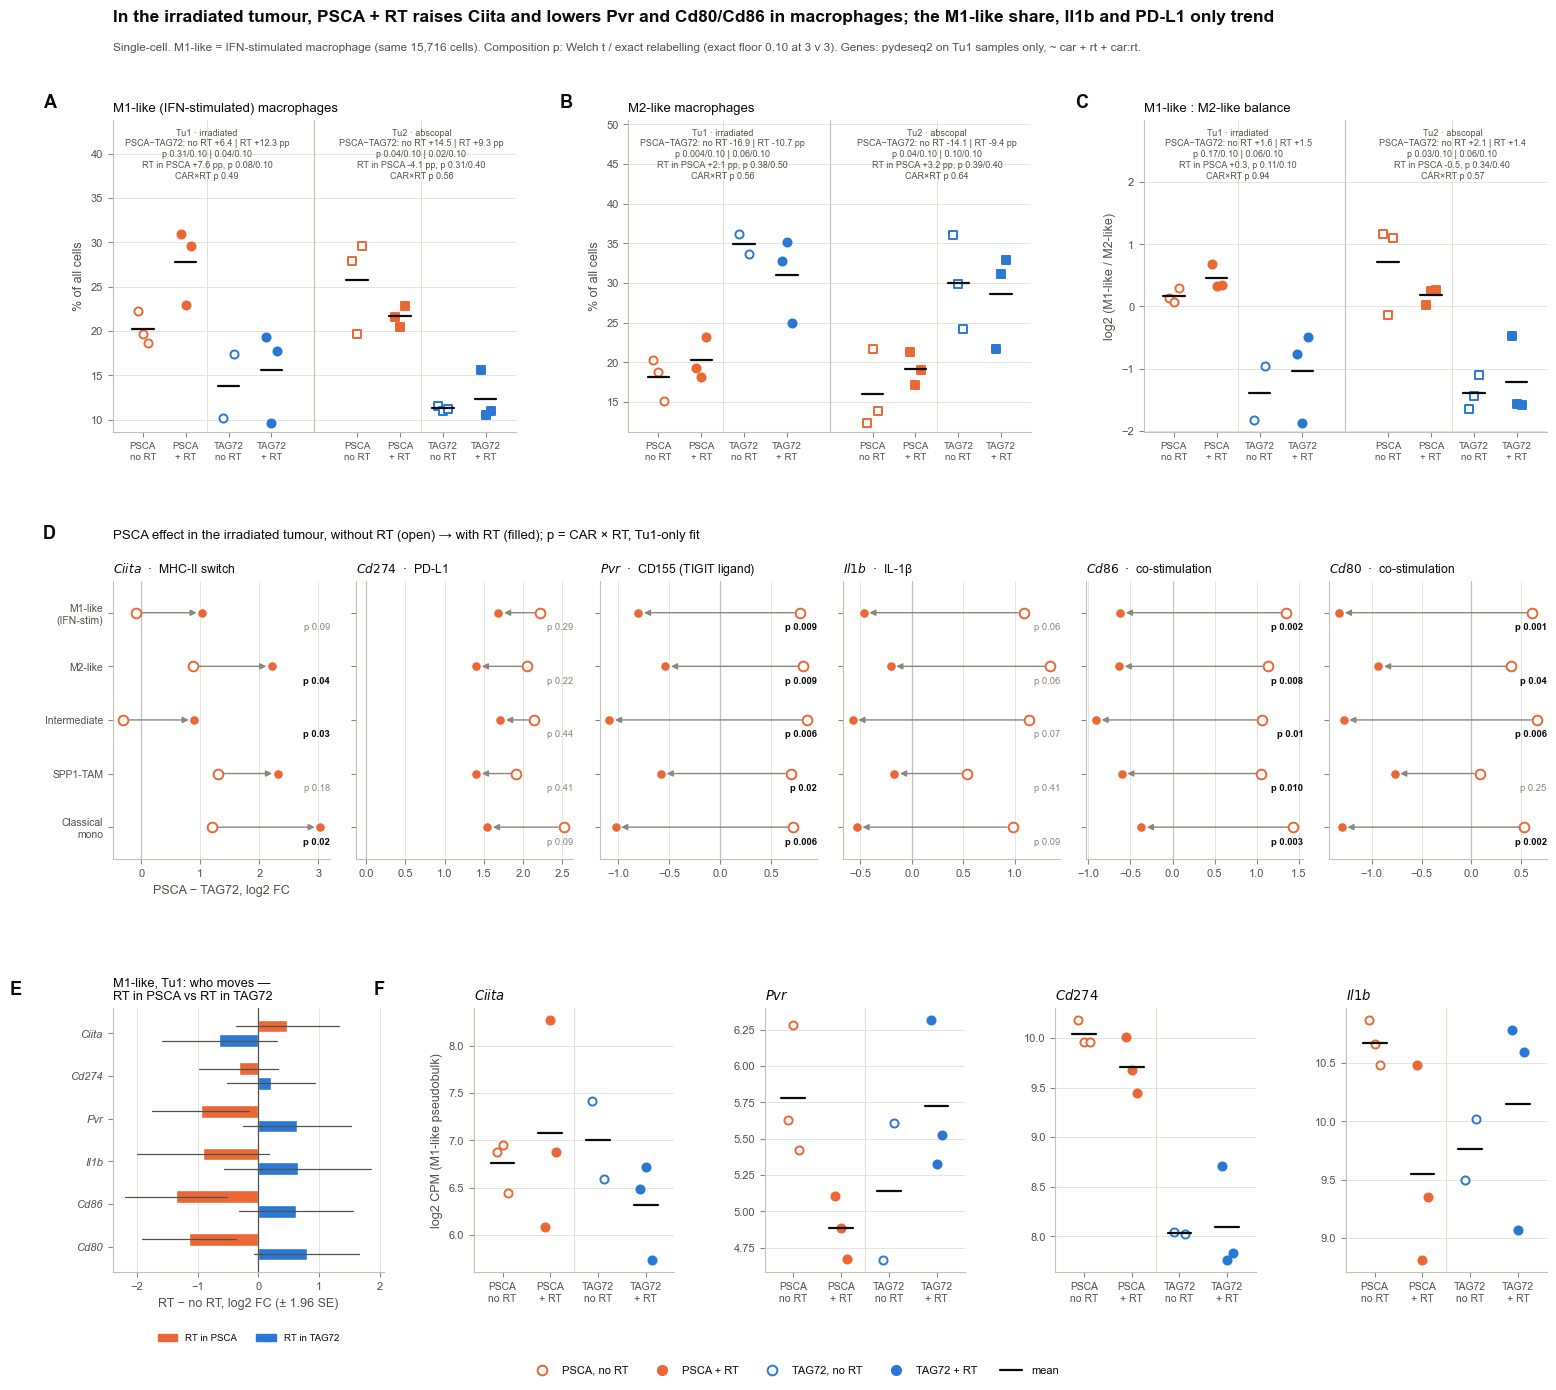

In [7]:
def comp_panel(ax, ct, title, letter):
    d = frac[[ct]].join(cm); sc = 1 if ct == "M1_to_M2_log2" else 100
    pos = {}
    for s, base in [(1, 0), (2, 5)]:
        for i, arm in enumerate(ARMS4):
            v = d[(d.arm == arm) & (d.site == s)][ct] * sc; x = base + i; pos[(arm, s)] = x
            col_ = CAR_COL[CAR_OF[arm]]
            xs = x + (np.linspace(-0.12, 0.12, len(v)) if len(v) > 1 else 0)
            ax.scatter(xs, v, s=34, marker="o" if s == 1 else "s", facecolor=col_ if RT_OF[arm] else "white",
                       edgecolor=col_, linewidth=1.4, zorder=3)
            if len(v): ax.plot([x - 0.25, x + 0.25], [v.mean()] * 2, color=INK, lw=1.6, zorder=4)
    ax.set_xticks([pos[(a, s)] for s in (1, 2) for a in ARMS4])
    ax.set_xticklabels([ARM_LAB[a] for s in (1, 2) for a in ARMS4], fontsize=7)
    ax.axvline(4, color=AXIS, lw=0.9); ax.axvline(1.5, color=GRID, lw=0.7); ax.axvline(6.5, color=GRID, lw=0.7)
    ax.yaxis.grid(True); ax.set_axisbelow(True); ax.set_xlim(-0.7, 8.7)
    ax.set_ylabel("log2 (M1-like / M2-like)" if ct == "M1_to_M2_log2" else "% of all cells")
    ax.set_title(title, loc="left", fontsize=9.5)
    ax.text(-0.17, 1.04, letter, transform=ax.transAxes, fontsize=13, weight="bold")
    yl = ax.get_ylim(); span = yl[1] - yl[0]; ax.set_ylim(yl[0], yl[1] + span * 0.5)
    unit = "" if ct == "M1_to_M2_log2" else " pp"
    for s, x0, lab in [(1, 1.5, "Tu1 · irradiated"), (2, 6.5, "Tu2 · abscopal")]:
        P = COMPE[(COMPE.cell_type == ct) & (COMPE.effect == f"PSCA Tu{s}")].set_index("part")
        R = COMPE[(COMPE.cell_type == ct) & (COMPE.effect == ("direct RT" if s == 1 else "indirect RT"))].set_index("part")
        lines = [lab,
                 f"PSCA−TAG72: no RT {P.loc['no RT', 'est']:+.1f} | RT {P.loc['RT', 'est']:+.1f}{unit}",
                 f"p {fmt_p(P.loc['no RT', 'welch'])}/{fmt_p(P.loc['no RT', 'p'])} | {fmt_p(P.loc['RT', 'welch'])}/{fmt_p(P.loc['RT', 'p'])}",
                 f"RT in PSCA {R.loc['PSCA', 'est']:+.1f}{unit}, p {fmt_p(R.loc['PSCA', 'welch'])}/{fmt_p(R.loc['PSCA', 'p'])}",
                 f"CAR×RT p {fmt_p(P.loc['CARxRT', 'p'])}"]
        ax.text(x0, yl[1] + span * 0.46, "\n".join(lines), ha="center", va="top", fontsize=6.5, color=INK2, linespacing=1.25)


MAC_GROUPS = ["IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "SPP1_TAM", "Classical_Mono"]
GENES_D = [("Ciita", "MHC-II switch"), ("Cd274", "PD-L1"), ("Pvr", "CD155 (TIGIT ligand)"), ("Il1b", "IL-1β"),
           ("Cd86", "co-stimulation"), ("Cd80", "co-stimulation")]
mac1 = PSF[(PSF.site == 1) & PSF.group.isin(MAC_GROUPS)]
bothm = DE[(DE.contrast == "CARxRT") & DE.group.isin(MAC_GROUPS)].set_index(["group", "gene"]).pvalue

fig = plt.figure(figsize=(15.5, 13.8))
gs = GridSpec(3, 1, height_ratios=[1.12, 1.0, 0.95], hspace=0.52, left=0.06, right=0.985, top=0.905, bottom=0.07)
fig.suptitle("In the irradiated tumour, PSCA + RT raises Ciita and lowers Pvr and Cd80/Cd86 in macrophages; "
             "the M1-like share, Il1b and PD-L1 only trend", x=0.06, y=0.985, ha="left", fontsize=12.5, weight="bold")
fig.text(0.06, 0.955, "Single-cell. M1-like = IFN-stimulated macrophage (same 15,716 cells). Composition p: Welch t / exact relabelling "
         "(exact floor 0.10 at 3 v 3). Genes: pydeseq2 on Tu1 samples only, ~ car + rt + car:rt.", fontsize=8.5, color=INK2)
r1 = GridSpecFromSubplotSpec(1, 3, gs[0], wspace=0.28)
comp_panel(fig.add_subplot(r1[0]), "M1_like_Mac", "M1-like (IFN-stimulated) macrophages", "A")
comp_panel(fig.add_subplot(r1[1]), "M2_like_Mac", "M2-like macrophages", "B")
comp_panel(fig.add_subplot(r1[2]), "M1_to_M2_log2", "M1-like : M2-like balance", "C")

# D: PSCA effect without vs with RT, Tu1-only fit, per gene x macrophage group
r2 = GridSpecFromSubplotSpec(1, len(GENES_D), gs[1], wspace=0.12)
MD = []
for j, (gname, glab) in enumerate(GENES_D):
    ax = fig.add_subplot(r2[j])
    for i, grp in enumerate(MAC_GROUPS):
        r = mac1[(mac1.group == grp) & (mac1.gene == gname)].set_index("contrast")
        if r.empty: continue
        a, b = r.loc["PSCA_noRT", "log2FoldChange"], r.loc["PSCA_RT", "log2FoldChange"]
        ax.annotate("", xy=(b, -i), xytext=(a, -i), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.0, shrinkA=4, shrinkB=4))
        ax.plot(a, -i, "o", mfc="white", mec=C_PSCA, mew=1.4, ms=7, zorder=3)
        ax.plot(b, -i, "o", color=C_PSCA, ms=7, mec="white", mew=0.8, zorder=4)
        p = r.loc["CARxRT", "pvalue"]
        ax.text(1.0, -i - 0.32, f"p {fmt_p(p)}", transform=ax.get_yaxis_transform(), ha="right", fontsize=6.8,
                color=INK if p < 0.05 else MUTED, weight="bold" if p < 0.05 else "normal")
        MD.append(dict(gene=gname, group=grp, psca_noRT=a, psca_RT=b, rt_in_psca=r.loc["RT_in_PSCA", "log2FoldChange"],
                       rt_in_tag72=r.loc["RT_in_TAG72", "log2FoldChange"], carxrt=r.loc["CARxRT", "log2FoldChange"],
                       p_carxrt_tu1=p, p_carxrt_bothsites=bothm.get((grp, gname), np.nan), n=r.n.iloc[0]))
    ax.axvline(0, color=AXIS, lw=0.9); ax.xaxis.grid(True); ax.set_axisbelow(True)
    ax.set_yticks([-i for i in range(len(MAC_GROUPS))])
    ax.set_yticklabels([NAME[g] for g in MAC_GROUPS] if j == 0 else [], fontsize=7.5)
    ax.set_ylim(-len(MAC_GROUPS) + 0.4, 0.6)
    ax.set_title(f"$\\it{{{gname}}}$  ·  {glab}", loc="left", fontsize=8.8)
    if j == 0:
        ax.set_xlabel("PSCA − TAG72, log2 FC")
MDD = pd.DataFrame(MD); MDD.to_csv(OUT/"fig2_mac_genes_tu1.csv", index=False)
fig.text(0.015, gs[1].get_position(fig).y1 + 0.03, "D", fontsize=13, weight="bold")
fig.text(0.06, gs[1].get_position(fig).y1 + 0.03,
         "PSCA effect in the irradiated tumour, without RT (open) → with RT (filled); p = CAR × RT, Tu1-only fit",
         fontsize=9.5, color=INK)

# E: decomposition (RT effect in PSCA vs TAG72, M1-like) + F: per-sample expression
r3 = GridSpecFromSubplotSpec(1, 5, gs[2], width_ratios=[1.35, 1, 1, 1, 1], wspace=0.42)
ax = fig.add_subplot(r3[0]); ax.text(-0.38, 1.05, "E", transform=ax.transAxes, fontsize=13, weight="bold")
m1 = mac1[mac1.group == "IFN_stimulated_Mac"]
for i, (gname, _) in enumerate(GENES_D):
    r = m1[m1.gene == gname].set_index("contrast")
    if r.empty: continue
    for part, col_, off in [("RT_in_PSCA", C_PSCA, 0.17), ("RT_in_TAG72", C_TAG72, -0.17)]:
        e = r.loc[part]
        ax.barh(-i + off, e.log2FoldChange, height=0.3, color=col_, edgecolor="white", linewidth=1)
        ax.plot([e.log2FoldChange - 1.96 * e.lfcSE, e.log2FoldChange + 1.96 * e.lfcSE], [-i + off] * 2, color=INK2, lw=0.9)
ax.axvline(0, color=INK2, lw=0.9); ax.set_yticks([-i for i in range(len(GENES_D))])
ax.set_yticklabels([g for g, _ in GENES_D], style="italic"); ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.set_xlabel("RT − no RT, log2 FC (± 1.96 SE)")
ax.set_title("M1-like, Tu1: who moves —\nRT in PSCA vs RT in TAG72", loc="left", fontsize=9.2)
ax.legend(handles=[mpl.patches.Patch(color=C_PSCA, label="RT in PSCA"), mpl.patches.Patch(color=C_TAG72, label="RT in TAG72")],
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=7)

pm = PBM[(PBM.group == "IFN_stimulated_Mac") & (PBM.n_cells >= MIN_CELLS_PB)]
ex = L.loc[pm.index, ["Ciita", "Pvr", "Cd274", "Il1b"]].copy(); ex.index = pm["sample"].values
ex["arm"], ex["site"] = pm.arm.values, pm.site.values
ex.to_csv(OUT/"fig2_m1_expression_per_sample.csv")
for j, gname in enumerate(["Ciita", "Pvr", "Cd274", "Il1b"]):
    ax = fig.add_subplot(r3[j + 1])
    strip(ax, ex, gname, site=1, scale=1, ylab="log2 CPM (M1-like pseudobulk)" if j == 0 else None)
    ax.set_title(f"$\\it{{{gname}}}$", loc="left", fontsize=9.5)
    if j == 0: ax.text(-0.5, 1.05, "F", transform=ax.transAxes, fontsize=13, weight="bold")
legend_arms(fig, y=-0.012)
for ext in ("png", "pdf"): fig.savefig(OUT/f"Figure2_macrophages_irradiated.{ext}", bbox_inches="tight")
plt.show()

## 6. Captions and summary

In [8]:
def g_(gene, grp):
    r = MDD[(MDD.gene == gene) & (MDD.group == grp)]
    return r.iloc[0] if len(r) else None


cpool = CD8E[(CD8E.effect == "direct RT") & (CD8E.part == "pooled")].set_index("marker")
c1 = COMPE.set_index(["cell_type", "effect", "part"])
cap = f"""# Captions — PSCA + RT figures

**Figure 1. In the irradiated tumour, RT goes with more armed, Cxcr3+ CD8 T cells in both CAR arms.**
Single-cell data, Tu1 (the irradiated tumour of RT mice, and the matched tumour of no-RT mice); one dot per tumour with ≥ {MIN_CELLS_FRAC} CD8 cells.
**(A)** Share of CD8 cells with ≥ 1 read of each marker; open = no RT, filled = RT; orange = PSCA, blue = TAG72; bar = mean.
RT effects pooled over the two CARs: Gzmb+ {cpool.loc['Gzmb+','est']:+.0f} pp (p {fmt_p(cpool.loc['Gzmb+','p'])}), Cxcr3+ {cpool.loc['Cxcr3+','est']:+.0f} pp (p {fmt_p(cpool.loc['Cxcr3+','p'])}),
Ccr5+ {cpool.loc['Ccr5+','est']:+.0f} pp (p {fmt_p(cpool.loc['Ccr5+','p'])}), ≥ 2 inhibitory receptors {cpool.loc['IR_ge2','est']:+.0f} pp (p {fmt_p(cpool.loc['IR_ge2','p'])}),
Tcf7+ {cpool.loc['Tcf7+','est']:+.0f} pp (p {fmt_p(cpool.loc['Tcf7+','p'])}), Tox+ {cpool.loc['Tox+','est']:+.0f} pp (p {fmt_p(cpool.loc['Tox+','p'])}).
**(B)** RT − no RT per CAR (circles) and pooled (diamond), 95% pooled-variance t CIs; exact relabelling p for the pooled effect and for CAR × RT.
No single-CAR RT effect can reach p < 0.10 at 3 v 3.
**(C)** CD8 pseudobulk, Tu1-only pydeseq2 (`~ car + rt + car:rt`): RT effect in PSCA vs TAG72, ± 1.96 SE; p = CAR × RT. With RT, PSCA CD8 cells lose Nr4a1, Nr4a3 and Klf2 while TAG72 CD8 cells gain them (p 0.005–0.013), and gain Cxcr6 (p 0.035).
**(D)** CD8 cells per tumour (log scale); the dashed line is the inclusion threshold. Interpret A–C with these denominators in mind.

**Figure 2. In the irradiated tumour, PSCA + RT raises Ciita and lowers Pvr and Cd80/Cd86 in macrophages; the M1-like share, Il1b and PD-L1 only trend.**
M1-like = the IFN-stimulated macrophage state (identical cell set). Circles = Tu1, squares = Tu2.
**(A–C)** Share of all cells per tumour, and the log2 M1:M2 ratio. Annotations give PSCA − TAG72 within each RT stratum and the RT effect within PSCA, with Welch t / exact relabelling p.
M1-like, Tu1: PSCA − TAG72 {c1.loc[('M1_like_Mac','PSCA Tu1','no RT'),'est']:+.1f} pp without RT, {c1.loc[('M1_like_Mac','PSCA Tu1','RT'),'est']:+.1f} pp with RT;
RT within PSCA {c1.loc[('M1_like_Mac','direct RT','PSCA'),'est']:+.1f} pp (Welch p {fmt_p(c1.loc[('M1_like_Mac','direct RT','PSCA'),'welch'])}; exact {fmt_p(c1.loc[('M1_like_Mac','direct RT','PSCA'),'p'])}),
RT within TAG72 {c1.loc[('M1_like_Mac','direct RT','TAG72'),'est']:+.1f} pp; CAR × RT exact p {fmt_p(c1.loc[('M1_like_Mac','direct RT','CARxRT'),'p'])}.
RT raises M2-like cells in PSCA too, so the log2 M1:M2 balance is no more PSCA-shifted with RT than without (CAR × RT p {fmt_p(c1.loc[('M1_to_M2_log2','PSCA Tu1','CARxRT'),'p'])}).
**(D)** PSCA − TAG72 log2 fold change in the irradiated tumour without RT (open) and with RT (filled), per macrophage group; p = CAR × RT from the Tu1-only fit (bold if < 0.05).
**(E)** Which arm moves: RT effect within PSCA vs within TAG72 in M1-like macrophages, Tu1. An interaction can come from PSCA falling, TAG72 rising, or both.
**(F)** Per-tumour log2 CPM in the M1-like pseudobulk, Tu1.

*Caveats.* 2–3 tumours per arm; per-arm RT effects are not significant on their own, so these are CAR × RT associations, not proof that RT improves PSCA.
The core PSCA interferon program (IFN-γ, ISG, Cxcl9) is about the same size with and without RT (interaction p 0.4–0.8; `mhcCytotoxExhaustion/03`).
"""
open(OUT/"captions.md", "w").write(cap)

print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print("\n[Fig 1] CD8, direct RT pooled over CARs (pp, exact p):")
print(cpool[["est", "lo", "hi", "p"]].round(3).to_string())
print("\n[Fig 1] CD8 CAR x RT (pp, exact p):")
print(CD8E[(CD8E.effect == "direct RT") & (CD8E.part == "CARxRT")].set_index("marker")[["est", "p"]].round(3).to_string())
print("\n[Fig 1C] CD8 genes, Tu1-only fit:"); print(pd.DataFrame(GC).round(3).to_string(index=False))
print("\n[Fig 2A-C] composition:")
print(COMPE[COMPE.part.isin(["no RT", "RT", "PSCA", "TAG72", "CARxRT"]) & COMPE.effect.isin(["PSCA Tu1", "direct RT"])]
      [["cell_type", "effect", "part", "est", "p", "welch"]].round(3).to_string(index=False))
print("\n[Fig 2D] macrophage genes, Tu1-only CAR x RT p (both-site p in brackets):")
t = MDD.assign(s=lambda d: d.carxrt.round(2).astype(str) + " p" + d.p_carxrt_tu1.map(fmt_p) + " [" + d.p_carxrt_bothsites.map(fmt_p) + "]")
print(t.pivot(index="gene", columns="group", values="s").to_string())
print(f"\n[files] {OUT}")
print("=" * 100)

SUMMARY — report these back

[Fig 1] CD8, direct RT pooled over CARs (pp, exact p):
            est      lo      hi     p
marker                               
Gzmb+    30.215   5.399  55.030  0.03
Prf1+    -2.161  -9.852   5.529  0.54
Cxcr3+   12.518   3.073  21.963  0.01
Ccr5+    21.952   7.104  36.799  0.03
Cxcr6+   14.389  -4.894  33.673  0.14
IR_ge2   17.323  -0.741  35.386  0.03
Pdcd1+   -3.003 -13.183   7.178  0.50
Havcr2+   8.883   0.168  17.597  0.04
Lag3+     7.701   1.578  13.823  0.03
Tigit+    5.140  -3.874  14.154  0.19
Tox+    -18.145 -39.921   3.630  0.07
Tcf7+   -19.871 -32.866  -6.876  0.05

[Fig 1] CD8 CAR x RT (pp, exact p):
            est     p
marker               
Gzmb+    13.896  0.66
Prf1+    11.110  0.12
Cxcr3+   -7.556  0.61
Ccr5+    26.708  0.21
Cxcr6+   18.318  0.35
IR_ge2   -3.256  0.92
Pdcd1+   -6.124  0.50
Havcr2+   9.168  0.37
Lag3+    10.155  0.20
Tigit+   -1.448  0.90
Tox+    -10.938  0.59
Tcf7+   -32.213  0.13

[Fig 1C] CD8 genes, Tu1-only fit:
 gen